# TicketIQ: pipeline runner
Runs the whole project as a pipeline of numbered scripts. Each stage reads and writes files on disk, so any step can be re-run on its own.

| Step | Script | Output |
|---|---|---|
| 1 | `01_download_data.py` | `data/processed/`, data overview plot, priority-map check |
| 2 | `02_train_baseline.py` | TF-IDF + LogReg baseline |
| 3 | `03_train_distilbert.py` | fine-tuned DistilBERT in `models/` |
| 4 | `04_evaluate.py` | metrics, plots, error analysis in `reports/` |
| 5 | `05_api_smoke_test.py` | FastAPI end-to-end check |
| 6 | pytest | unit + API tests |

In [1]:
import os, sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "ticketclf").exists()), None)
assert ROOT is not None, "Open this notebook inside the project folder (the one containing src/ticketclf)"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)

Project root: e:\ML Projects\Ticket Intent Classifier


In [2]:
# Run once if packages are missing (uses the notebook's kernel / .venv)
# %pip install -q -r requirements.txt

## Step 1: Download and prepare data

Splits: {'train': (9002, 3), 'val': (1001, 3), 'test': (3080, 3)} | intents: 77

Samples per intent (train):
count     77.0
mean     116.9
std       29.6
min       32.0
25%      101.0
50%      114.0
75%      143.0
max      168.0

Words per query (train):
count    9002.0
mean       12.0
std         8.0
min         2.0
25%         7.0
50%        10.0
75%        13.0
max        79.0

Priority map OK. Intents per level: {'Medium': 30, 'Low': 34, 'High': 13}


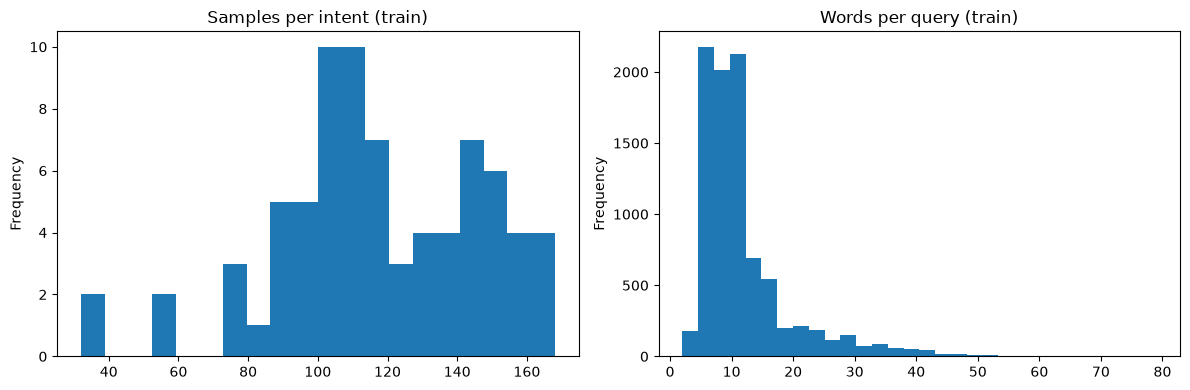

In [3]:
%run scripts/01_download_data.py

## Step 2: Baseline model

In [4]:
%run scripts/02_train_baseline.py

Baseline (TF-IDF + Logistic Regression):
      accuracy  macro_f1  weighted_f1  top3_accuracy
val     0.8861    0.8871       0.8853         0.9600
test    0.8867    0.8872       0.8872         0.9679


## Step 3: Fine-tune DistilBERT
CPU ~20-40 min, GPU a few minutes. Skipped automatically if a saved model exists. Use `%run scripts/03_train_distilbert.py --retrain` to train again.

e:\ML Projects\Ticket Intent Classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 935.11it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Epoch 1/4: 100%|██████████| 282/282 [12:19<00:00,  2.62s/it]


{'epoch': 1, 'train_loss': 3.136044627385782, 'val_accuracy': 0.7922077922077922, 'val_macro_f1': 0.7426853446968219, 'seconds': 760.0}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.56it/s]


...

  -> saved best model (val macro-F1 0.9018)


Epoch 4/4: 100%|██████████| 282/282 [11:19<00:00,  2.41s/it]


{'epoch': 4, 'train_loss': 0.21143896344071583, 'val_accuracy': 0.9080919080919081, 'val_macro_f1': 0.9119459906155821, 'seconds': 698.8}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.96it/s]


  -> saved best model (val macro-F1 0.9119)
Best val macro-F1: 0.9119
   epoch  train_loss  val_accuracy  val_macro_f1  seconds
0      1      3.1360        0.7922        0.7427    760.0
1      2      0.8696        0.8901        0.8933    752.4
2      3      0.3611        0.8991        0.9018    697.5
3      4      0.2114        0.9081        0.9119    698.8


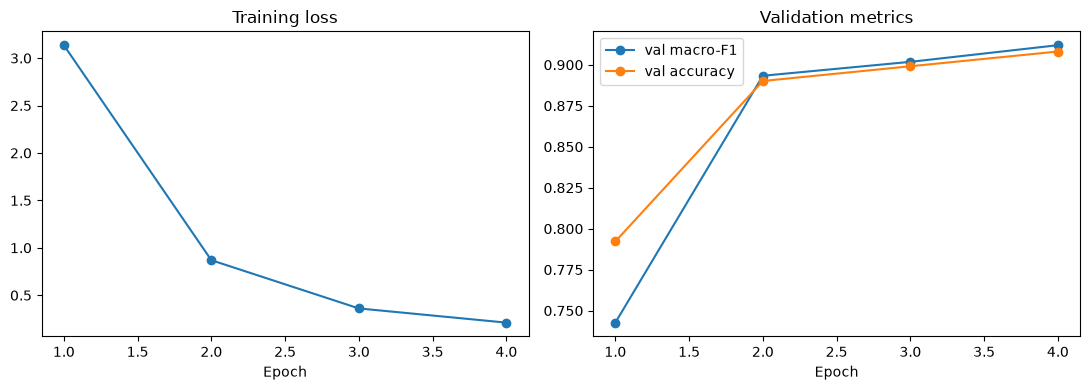

In [5]:
%run scripts/03_train_distilbert.py

## Step 4: Evaluation

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 948.15it/s]


=== Test set comparison ===
                         accuracy  macro_f1  weighted_f1  top3_accuracy
TF-IDF + LogReg            0.8867    0.8872       0.8872         0.9679
DistilBERT (fine-tuned)    0.9188    0.9185       0.9185         0.9776

=== Weakest intents ===
                                    intent  precision  recall     f1  support
0                       topping_up_by_card      0.784   0.725  0.753       40
1                      why_verify_identity      0.931   0.675  0.783       40
2                         compromised_card      0.882   0.750  0.811       40
3                    transfer_into_account      0.825   0.825  0.825       40
4  balance_not_updated_after_bank_transfer      0.865   0.800  0.831       40
5                         pending_transfer      0.795   0.875  0.833       40
6                        declined_transfer      1.000   0.725  0.841       40
7                       verify_my_identity      0.750   0.975  0.848       40
8                          tr

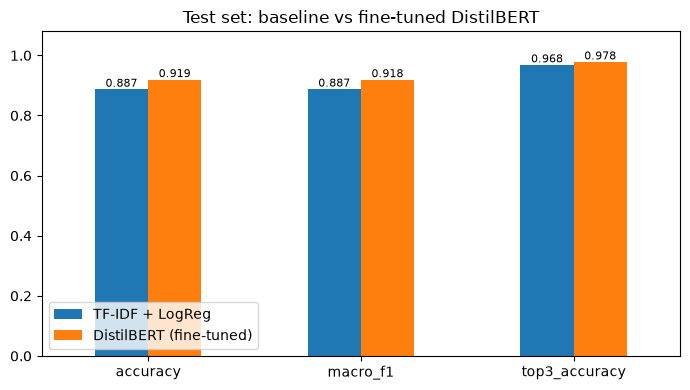

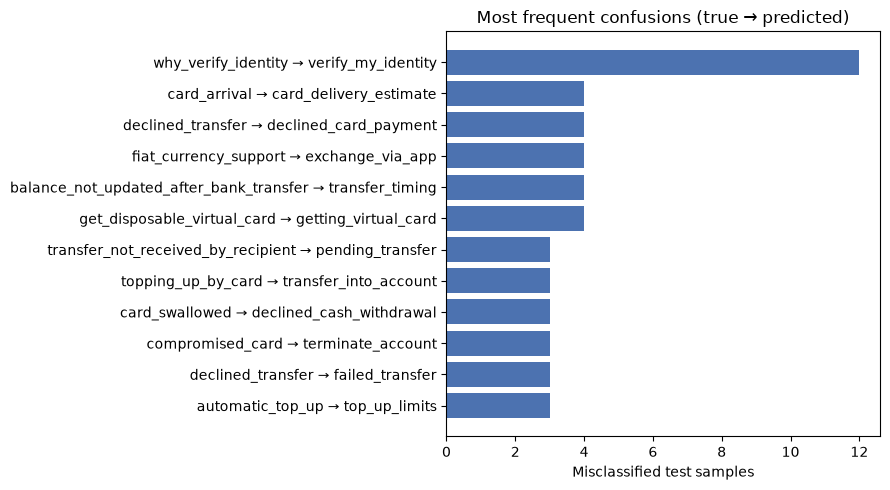

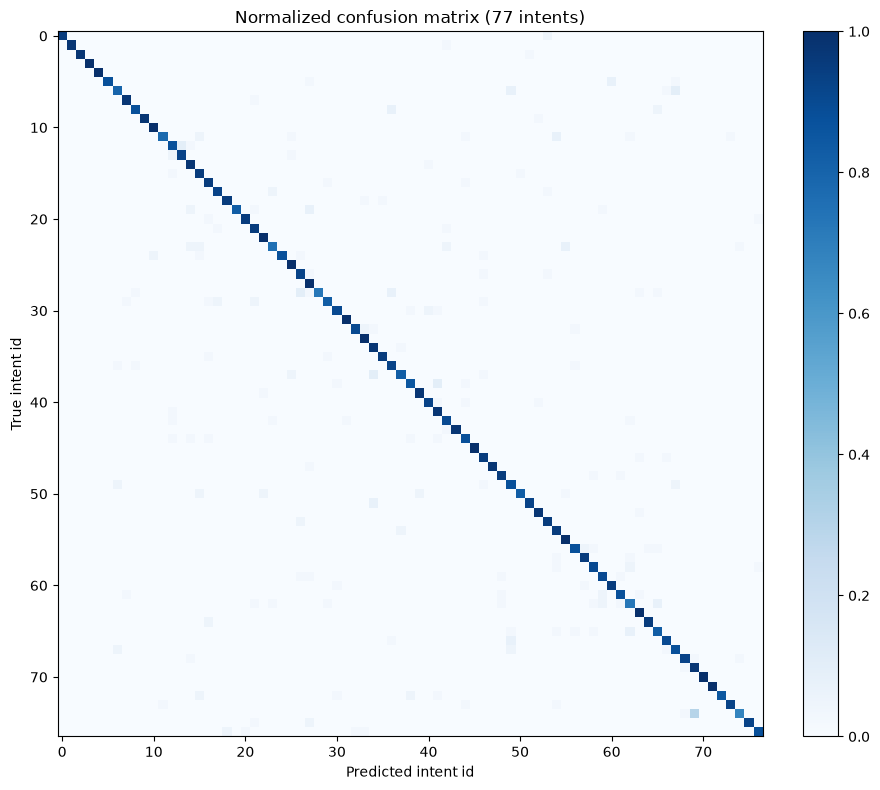

In [6]:
%run scripts/04_evaluate.py

## Step 5: API smoke test

In [7]:
%run scripts/05_api_smoke_test.py

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1385.09it/s]


health: {'status': 'ok', 'model_loaded': True}
single: {'intent': 'card_payment_not_recognised', 'confidence': 0.864, 'priority': 'High', 'needs_human_review': False, 'top_k': [{'intent': 'card_payment_not_recognised', 'confidence': 0.864}, {'intent': 'compromised_card', 'confidence': 0.0266}, {'intent': 'lost_or_stolen_card', 'confidence': 0.0192}]}

batch (5 tickets):
  High   | 0.86 | review=False | card_payment_not_recognised      | My card was stolen and I see payments I did not make
  Low    | 0.73 | review=False | topping_up_by_card               | How do I top up my account?
  Low    | 0.95 | review=False | card_arrival                     | I still haven't received my card, where is it?
  High   | 0.98 | review=False | transaction_charged_twice        | Why was I charged twice for the same purchase?
  Medium | 0.12 | review=True  | top_up_reverted                  | blah blah something completely random

blank text status: 422
API smoke test finished. Run the server yourself: 

## Step 6: Tests

In [8]:
!{sys.executable} -m pytest -q

'e:\ML' is not recognized as an internal or external command,
operable program or batch file.


## Docker (run in a terminal after the model is trained)
```powershell
docker build -t ticketiq .
docker run -p 8000:8000 ticketiq
```